# 03 — Dispatch for all days (losses + coal tiers)

**Does:** runs the state-level dispatch model with distance-based transmission losses for every day from Jan 2020 to Mar 2025, with coal costs varying by state.

**Input:** `data/processed/india_electricity_data_updated.csv`, `data/raw/india_generator_stack.csv`, `data/raw/coal_cost_tiers.csv`, `data/raw/state_coordinates.csv`

**Output:** three tables in `data/processed/`, the input for forecasting (Part 2) and strategic bidding (Part 3):
- `dispatch_state_daily.csv`: one row per day and state (price, generation, imports, exports)
- `dispatch_flows_daily.csv`: one row per day and inter-state trade
- `dispatch_national_daily.csv`: one row per day (totals, price range, generation by fuel)

**Method:** the functions in `src/dispatch.py`, developed and validated in notebook 02. Checks: `.venv/bin/python -m pytest`.

## Assumptions

| Assumption | Value / note |
|---|---|
| Demand | `Max Demand Met` (daily peak, MW); excludes unmet shortage (~1 GW nationally on average) |
| States | 32; DVC excluded (demand data but no generator data) |
| Availability | Fixed share of nameplate, same in every season (solar 0.25, wind 0.30, coal 0.75, …) |
| Coal cost | By state tier: pithead 1,600 · near mines 2,200 · inland far 2,800 · coastal/imported 3,800 Rs/MWh |
| Other fuel costs | Solar/wind 0, hydro 1,000, lignite 2,300, nuclear/bio 3,500, gas 4,500, diesel 11,000 |
| Transmission | No line limits. Loss = min(0.5% + 4% × 1.2 × distance/1000 km, 10%), distance between state capitals |
| VOLL | Rs 10,000/MWh |
| Known data issue | Some DD & DNH rows in the raw file are column-shifted and not yet fixed in notebook 01 (<1% of national demand) |

In [1]:
import sys
sys.path.append("../src")

import time
import pandas as pd
import matplotlib.pyplot as plt

from dispatch import (load_generators, load_demand, load_coordinates, loss_matrix,
                      LossDispatchModel, run_all_days, PROCESSED)

## Step 1: inputs

In [2]:
gen = load_generators()                 # coal tiers applied
demand = load_demand()                  # rows = dates, columns = states
states = list(demand.columns)
loss = loss_matrix(load_coordinates(), states)

print(f"{len(states)} states, {len(demand)} days ({demand.index.min().date()} to {demand.index.max().date()})")
print("Missing demand values:", demand.isna().sum().sum())
pd.read_csv("../data/raw/coal_cost_tiers.csv")

32 states, 1917 days (2020-01-01 to 2025-03-31)
Missing demand values: 0


,State,Tier,Coal_Cost_Rs_per_MWh
0,Chhattisgarh,Pithead,1600
1,ER Odisha,Pithead,1600
2,MP,Pithead,1600
3,Telangana,Pithead,1600
4,West Bengal,Near mines,2200
5,NR UP,Near mines,2200
6,Bihar,Near mines,2200
7,Assam,Near mines,2200
8,Haryana,Inland far,2800
9,Punjab,Inland far,2800


## Step 2: how coal tiers change the supply curve

Before: all 216 GW of coal at one cost, so one flat step. After: a staircase through the coal range.

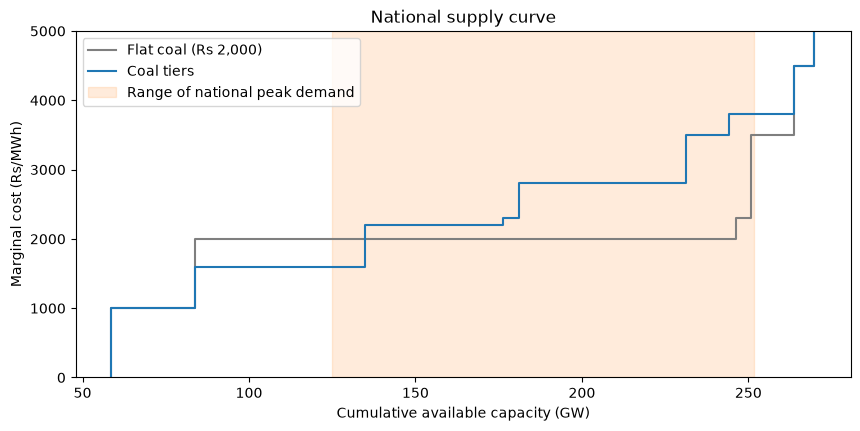

In [3]:
def supply_curve(g):
    s = (g.groupby("Marginal_Cost_Rs_per_MWh")["Available_MW"].sum()
           .sort_index().reset_index())
    s["Cum_GW"] = s["Available_MW"].cumsum() / 1000
    return s

flat = supply_curve(load_generators(coal_tiers=False))
tiered = supply_curve(gen)

fig, ax = plt.subplots(figsize=(10, 4.5))
for s, label, color in [(flat, "Flat coal (Rs 2,000)", "tab:gray"), (tiered, "Coal tiers", "tab:blue")]:
    ax.step(s["Cum_GW"], s["Marginal_Cost_Rs_per_MWh"], where="pre", label=label, color=color)
national_peak = demand.sum(axis=1)
ax.axvspan(national_peak.min() / 1000, national_peak.max() / 1000, color="tab:orange", alpha=0.15,
           label="Range of national peak demand")
ax.set_xlabel("Cumulative available capacity (GW)")
ax.set_ylabel("Marginal cost (Rs/MWh)")
ax.set_ylim(0, 5000)
ax.set_title("National supply curve")
ax.legend()
plt.show()

## Step 3: build the model once, run every day

In [4]:
model = LossDispatchModel(gen, loss, states)
print(f"Variables: {len(model.c)}, equations: {model.A_eq.shape[0]}")

t0 = time.time()
state_daily, flows_daily, national_daily = run_all_days(model, demand)
print(f"Solved {len(national_daily)} days in {time.time() - t0:.1f} s")

Variables: 1185, equations: 32


Solved 1917 days in 8.8 s


## Step 4: validation

In [5]:
# 1. Spot check: 21 July 2024 matches a single-day solve
single = model.solve(demand.loc["2024-07-21"])
day = national_daily.set_index("Date").loc["2024-07-21"]
print("1. 21 Jul 2024 cost, full run vs single solve:",
      round(day["Total_cost_Rs_per_h"]), round(single["total_cost"]))

# 2. Energy balance every day: extra generation = losses
fuel_cols = [c for c in national_daily.columns if c.endswith("_MW") and c not in
             ("Demand_MW", "Unserved_MW", "Traded_MW", "Losses_MW")]
extra = national_daily[fuel_cols].sum(axis=1) - national_daily["Demand_MW"] + national_daily["Unserved_MW"]
print("2. Largest energy-balance error (MW):", (extra - national_daily["Losses_MW"]).abs().max())

# 3. Sanity
print("3. Negative prices:", (state_daily["Price"] < 0).sum(),
      "| days with unserved demand:", (national_daily["Unserved_MW"] > 1e-6).sum())

# 4. Losses as a share of traded power (India: ~3-4%)
print(f"4. Losses / traded power: {100 * national_daily['Losses_MW'].sum() / national_daily['Traded_MW'].sum():.2f}%")

1. 21 Jul 2024 cost, full run vs single solve: 317767055 317767055
2. Largest energy-balance error (MW): 4.8203219193965197e-11
3. Negative prices: 0 | days with unserved demand: 0
4. Losses / traded power: 3.83%


## Step 5: does the price move now?

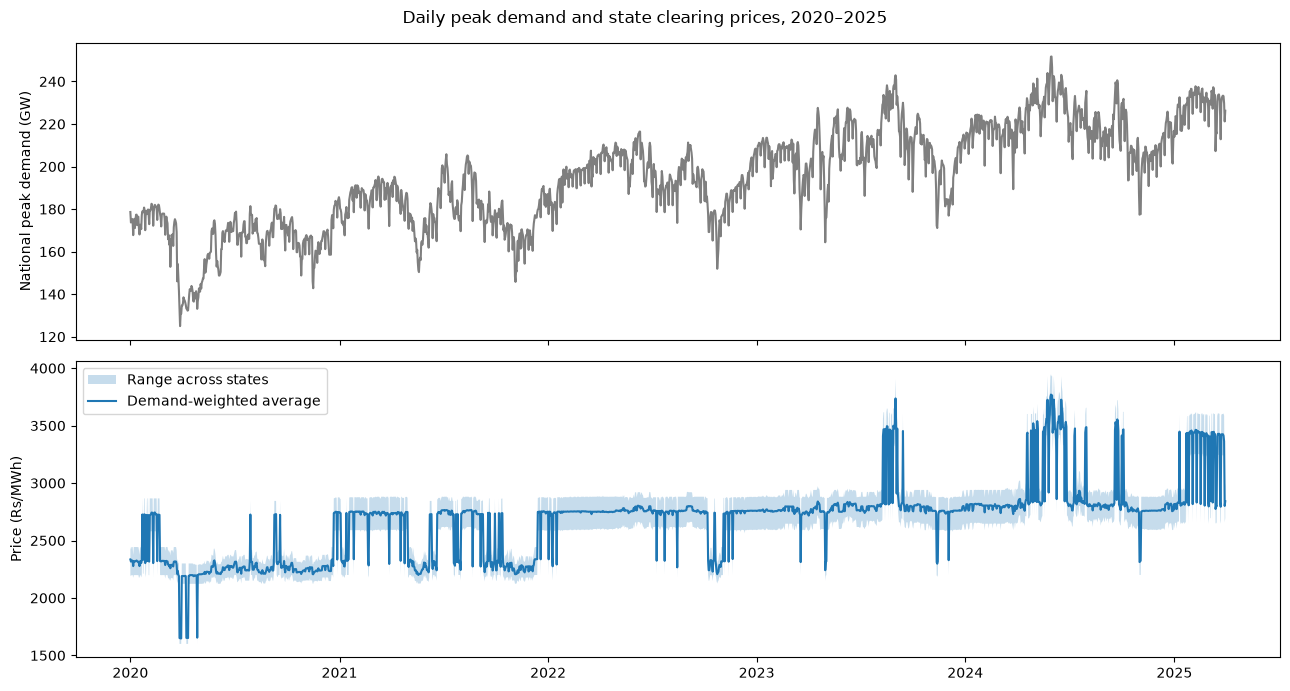

count    1917.0
mean     2677.0
std       324.0
min      1648.0
25%      2323.0
50%      2753.0
75%      2796.0
max      3770.0
Name: Price_avg, dtype: float64


In [6]:
nd = national_daily.set_index("Date")

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(nd.index, nd["Demand_MW"] / 1000, color="tab:gray")
ax[0].set_ylabel("National peak demand (GW)")
ax[1].fill_between(nd.index, nd["Price_min"], nd["Price_max"], alpha=0.25, label="Range across states")
ax[1].plot(nd.index, nd["Price_avg"], label="Demand-weighted average")
ax[1].set_ylabel("Price (Rs/MWh)")
ax[1].legend(loc="upper left")
fig.suptitle("Daily peak demand and state clearing prices, 2020–2025")
plt.tight_layout()
plt.show()

print(nd["Price_avg"].describe().round(0))

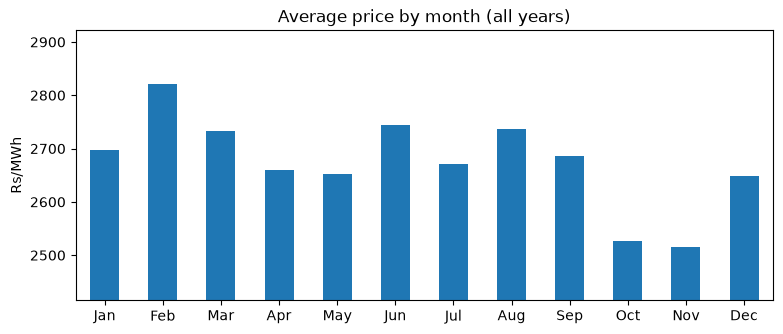

In [7]:
# Seasonal pattern: average price by month
import calendar

monthly = nd.groupby(nd.index.month)["Price_avg"].mean()
monthly.index = [calendar.month_abbr[m] for m in monthly.index]

monthly.plot(kind="bar", figsize=(9, 3.5), color="tab:blue", rot=0,
             title="Average price by month (all years)", ylabel="Rs/MWh")
plt.ylim(monthly.min() - 100, monthly.max() + 100)
plt.show()

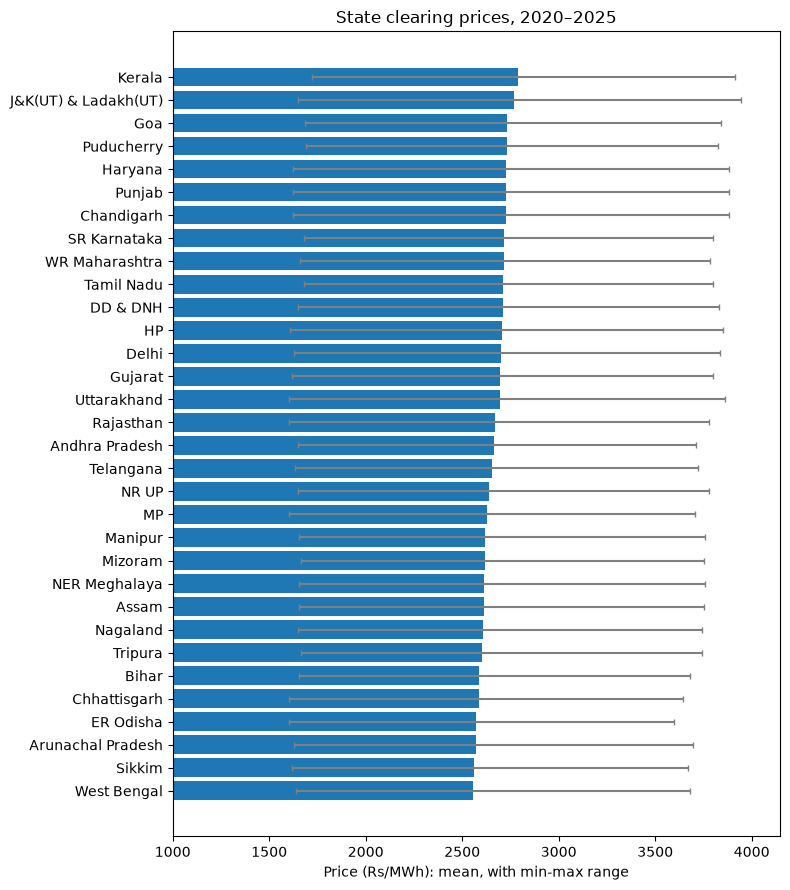

In [8]:
# Price by state: which states are expensive, and how much do they vary?
by_state = state_daily.groupby("State")["Price"].agg(["mean", "min", "max"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(by_state.index, by_state["mean"], xerr=[by_state["mean"] - by_state["min"],
                                                 by_state["max"] - by_state["mean"]],
        color="tab:blue", ecolor="gray", capsize=2)
ax.set_xlabel("Price (Rs/MWh): mean, with min-max range")
ax.set_title("State clearing prices, 2020–2025")
ax.set_xlim(1000, by_state["max"].max() + 200)
plt.tight_layout()
plt.show()

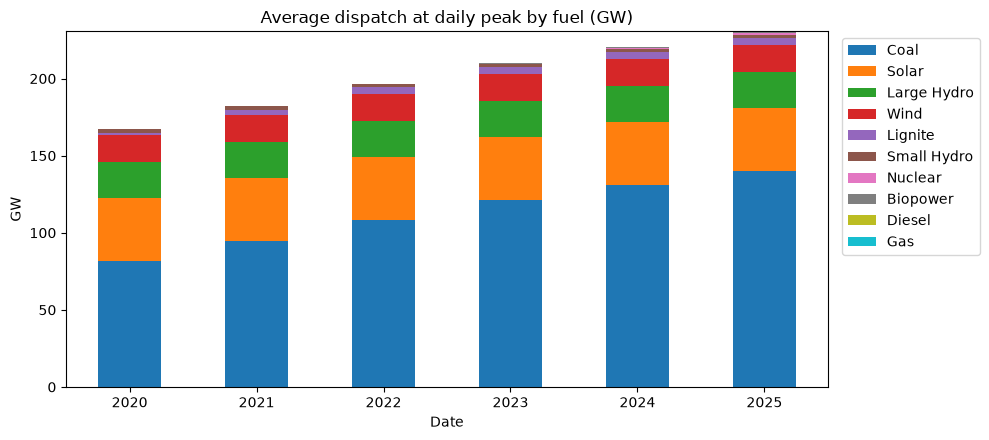

In [9]:
# Which generation sets the pace: national generation mix by year
mix = nd[fuel_cols].groupby(nd.index.year).mean() / 1000
mix.columns = [c.replace("_MW", "") for c in mix.columns]
mix = mix[mix.sum().sort_values(ascending=False).index]

mix.plot(kind="bar", stacked=True, figsize=(10, 4.5), rot=0,
         title="Average dispatch at daily peak by fuel (GW)", ylabel="GW")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Step 6: save the results

In [10]:
state_daily.to_csv(PROCESSED / "dispatch_state_daily.csv", index=False)
flows_daily.to_csv(PROCESSED / "dispatch_flows_daily.csv", index=False)
national_daily.to_csv(PROCESSED / "dispatch_national_daily.csv", index=False)

for name, df in [("state", state_daily), ("flows", flows_daily), ("national", national_daily)]:
    print(f"dispatch_{name}_daily.csv: {len(df):,} rows")

dispatch_state_daily.csv: 61,344 rows
dispatch_flows_daily.csv: 57,345 rows
dispatch_national_daily.csv: 1,917 rows
